In [1]:
import os
import ast
import numpy as np
import pandas as pd
import wfdb

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
PHYSIONET_DIR = "ptb-xl/1.0.3"

print("Using PTB-XL from PhysioNet")
print(PHYSIONET_DIR)

Using PTB-XL from PhysioNet
ptb-xl/1.0.3


In [3]:
BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3/"

database_url = BASE_URL + "ptbxl_database.csv"

df = pd.read_csv(
    database_url,
    index_col="ecg_id"
)

print("Dataset metadata loaded!")
print("Number of records:", len(df))

Dataset metadata loaded!
Number of records: 21799


In [5]:
scp_url = BASE_URL + "scp_statements.csv"

scp = pd.read_csv(
    scp_url,
    index_col=0
)

print("SCP statements loaded!")
print("Shape:", scp.shape)

SCP statements loaded!
Shape: (71, 12)


In [7]:
def get_label(scp_codes):

    codes = ast.literal_eval(scp_codes)

    diagnostic_codes = []

    for code, probability in codes.items():

        if code in scp.index:

            if scp.loc[code, "diagnostic"] == 1:

                if probability >= 50:
                    diagnostic_codes.append(code)

    if len(diagnostic_codes) == 0:
        return np.nan

    # Only NORM
    if diagnostic_codes == ["NORM"]:
        return 0

    # Any other diagnostic class
    return 1

In [8]:
df["target"] = df["scp_codes"].apply(get_label)

df = df.dropna(
    subset=["target"]
).copy()

df["target"] = df["target"].astype(int)

print(df["target"].value_counts())

target
1    11335
0     9038
Name: count, dtype: int64


In [9]:
normal_count = (
    df["target"] == 0
).sum()

abnormal_count = (
    df["target"] == 1
).sum()

print("Normal ECGs   :", normal_count)
print("Abnormal ECGs :", abnormal_count)
print("Total ECGs    :", len(df))

Normal ECGs   : 9038
Abnormal ECGs : 11335
Total ECGs    : 20373


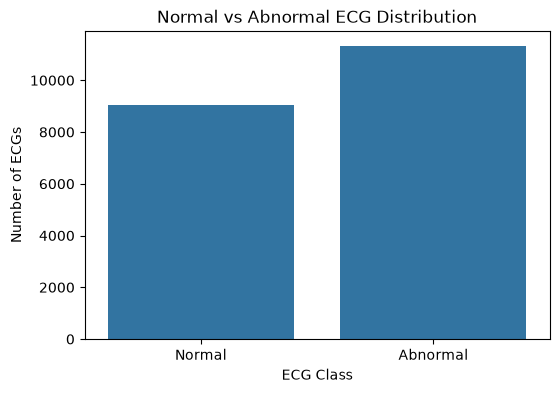

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(
    x=df["target"]
)

plt.xticks(
    [0, 1],
    ["Normal", "Abnormal"]
)

plt.xlabel("ECG Class")
plt.ylabel("Number of ECGs")
plt.title("Normal vs Abnormal ECG Distribution")

plt.show()

In [11]:
print(
    df["strat_fold"]
    .value_counts()
    .sort_index()
)

strat_fold
1     2034
2     2039
3     2066
4     2022
5     2029
6     2014
7     2043
8     2042
9     2034
10    2050
Name: count, dtype: int64


In [12]:
train_df = df[
    df["strat_fold"] <= 8
].copy()

val_df = df[
    df["strat_fold"] == 9
].copy()

test_df = df[
    df["strat_fold"] == 10
].copy()

print("Training records  :", len(train_df))
print("Validation records:", len(val_df))
print("Testing records   :", len(test_df))

Training records  : 16289
Validation records: 2034
Testing records   : 2050


In [13]:
train_small = train_df.sample(
    n=min(300, len(train_df)),
    random_state=42
)

val_small = val_df.sample(
    n=min(100, len(val_df)),
    random_state=42
)

test_small = test_df.sample(
    n=min(100, len(test_df)),
    random_state=42
)

print("Training:", len(train_small))
print("Validation:", len(val_small))
print("Testing:", len(test_small))

Training: 300
Validation: 100
Testing: 100


In [14]:
print("TRAINING")
print(train_small["target"].value_counts())

print("\nVALIDATION")
print(val_small["target"].value_counts())

print("\nTESTING")
print(test_small["target"].value_counts())

TRAINING
target
1    166
0    134
Name: count, dtype: int64

VALIDATION
target
0    50
1    50
Name: count, dtype: int64

TESTING
target
1    50
0    50
Name: count, dtype: int64


In [15]:
import requests
import tempfile
import os
import wfdb

def load_ecg_remote(filename):
    base_url = "https://physionet.org/files/ptb-xl/1.0.3/"
    
    header_url = base_url + filename + ".hea"
    data_url = base_url + filename + ".dat"
    
    with tempfile.TemporaryDirectory() as temp_dir:
        
        record_name = os.path.basename(filename)
        local_record = os.path.join(temp_dir, record_name)
        
        # Download header
        response = requests.get(header_url)
        response.raise_for_status()
        
        with open(local_record + ".hea", "wb") as f:
            f.write(response.content)
        
        # Download ECG data
        response = requests.get(data_url)
        response.raise_for_status()
        
        with open(local_record + ".dat", "wb") as f:
            f.write(response.content)
        
        # Read ECG
        signal, fields = wfdb.rdsamp(local_record)
        
    return signal

In [16]:
sample_filename = train_small.iloc[0]["filename_lr"]

print("ECG file:")
print(sample_filename)

signal = load_ecg_remote(sample_filename)

print("ECG shape:", signal.shape)

ECG file:
records100/11000/11393_lr
ECG shape: (1000, 12)


In [17]:
def extract_features(signal):
    features = []

    for lead in range(signal.shape[1]):
        x = signal[:, lead]

        features.extend([
            np.mean(x),
            np.std(x),
            np.min(x),
            np.max(x),
            np.sqrt(np.mean(x ** 2))
        ])

    return features

In [18]:
X_train = []
y_train = []

for _, row in train_small.iterrows():
    try:
        signal = load_ecg_remote(row["filename_lr"])
        features = extract_features(signal)

        X_train.append(features)
        y_train.append(row["target"])

    except Exception as e:
        print("Error:", row["filename_lr"], e)

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (300, 60)
y_train shape: (300,)


In [19]:
X_val = []
y_val = []

for _, row in val_small.iterrows():
    try:
        signal = load_ecg_remote(row["filename_lr"])
        features = extract_features(signal)

        X_val.append(features)
        y_val.append(row["target"])

    except Exception as e:
        print("Error:", row["filename_lr"], e)

X_val = np.array(X_val)
y_val = np.array(y_val)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_val shape: (100, 60)
y_val shape: (100,)


In [20]:
X_test = []
y_test = []

for _, row in test_small.iterrows():
    try:
        signal = load_ecg_remote(row["filename_lr"])
        features = extract_features(signal)

        X_test.append(features)
        y_test.append(row["target"])

    except Exception as e:
        print("Error:", row["filename_lr"], e)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (100, 60)
y_test shape: (100,)


In [21]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [22]:
y_prob = model.predict_proba(X_test)[:, 1]

print("First 10 probabilities:")
print(y_prob[:10])

First 10 probabilities:
[0.5710431  0.54014394 0.97271434 0.55225788 0.24209867 0.70768351
 0.16558073 0.29342182 0.26171755 0.4059231 ]


In [32]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Threshold,Accuracy,Precision,Recall,F1-Score,TP,TN,FP,FN
0,0.3,0.60,0.569,0.82,0.672,41,19,31,9
1,0.4,0.66,0.638,0.74,0.685,37,29,21,13
2,0.5,0.66,0.674,0.62,0.646,31,35,15,19
3,0.6,0.66,0.735,0.50,0.595,25,41,9,25
4,0.7,0.64,0.733,0.44,0.550,22,42,8,28


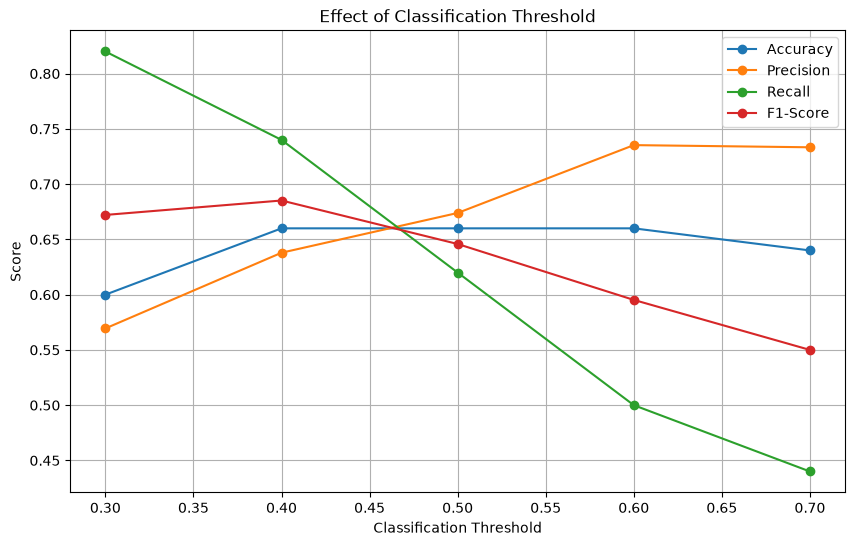

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Threshold"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["Threshold"],
    results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["Threshold"],
    results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["Threshold"],
    results_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Effect of Classification Threshold")
plt.legend()
plt.grid(True)

plt.show()

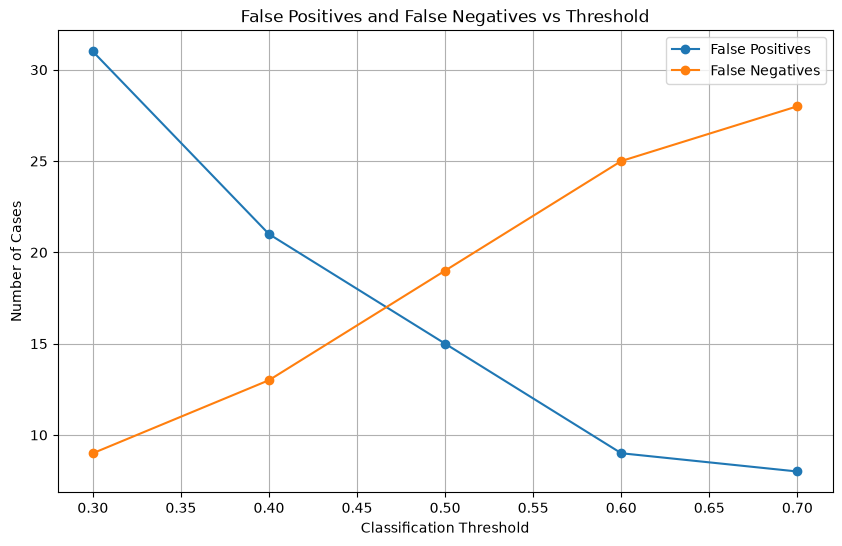

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Threshold"],
    results_df["False Positives"],
    marker="o",
    label="False Positives"
)

plt.plot(
    results_df["Threshold"],
    results_df["False Negatives"],
    marker="o",
    label="False Negatives"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Cases")
plt.title("False Positives and False Negatives vs Threshold")
plt.legend()
plt.grid(True)

plt.show()

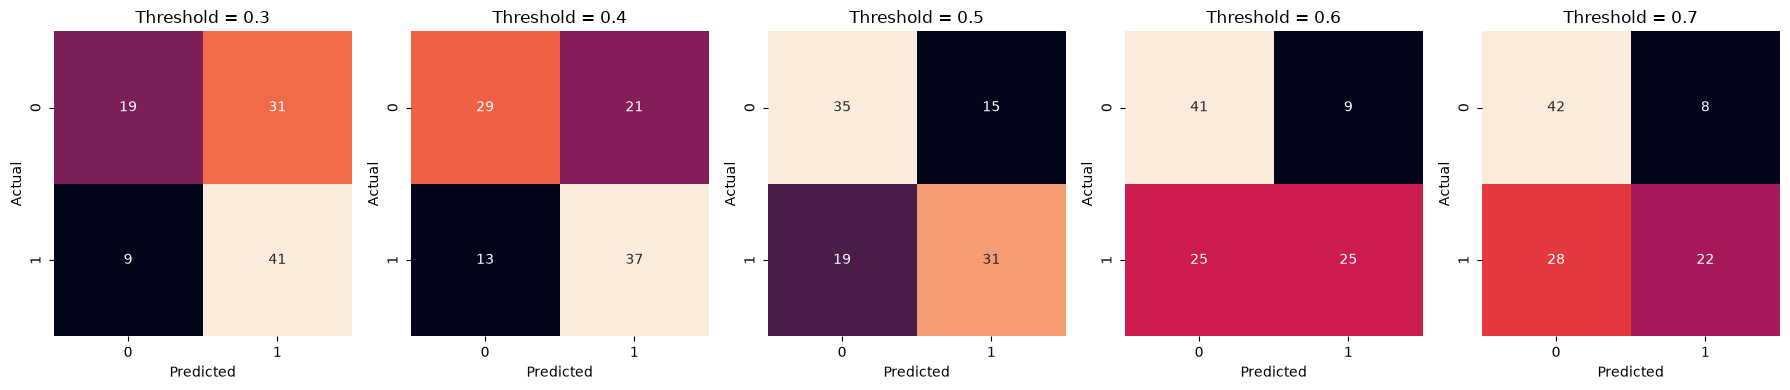

In [27]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, threshold in zip(axes, thresholds):

    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        ax=ax,
        cbar=False
    )

    ax.set_title(f"Threshold = {threshold}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [36]:
prediction_counts = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    normal_count = np.sum(y_pred == 0)
    abnormal_count = np.sum(y_pred == 1)

    prediction_counts.append({
        "Threshold": threshold,
        "Normal": normal_count,
        "Abnormal": abnormal_count
    })

prediction_df = pd.DataFrame(prediction_counts)

display(prediction_df)

,Threshold,Normal,Abnormal
0,0.3,28,72
1,0.4,42,58
2,0.5,54,46
3,0.6,66,34
4,0.7,70,30


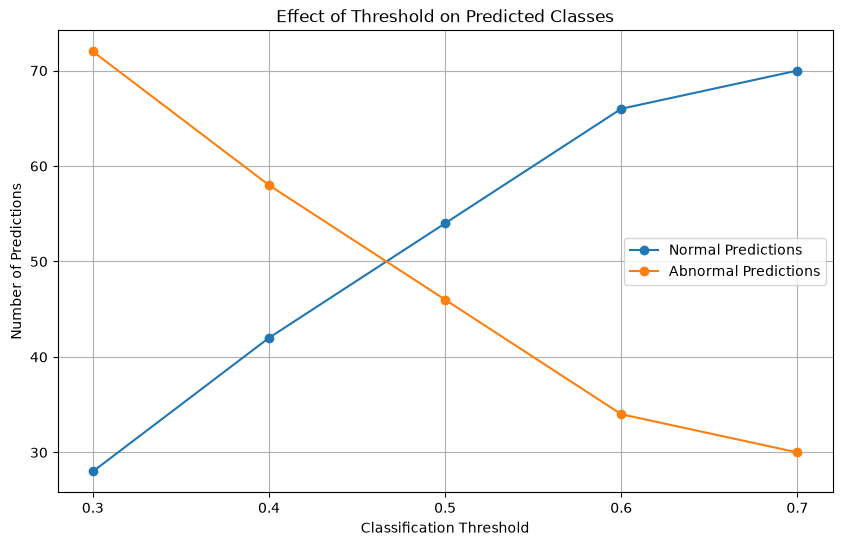

In [37]:
plt.figure(figsize=(10, 6))

plt.plot(
    prediction_df["Threshold"],
    prediction_df["Normal"],
    marker="o",
    label="Normal Predictions"
)

plt.plot(
    prediction_df["Threshold"],
    prediction_df["Abnormal"],
    marker="o",
    label="Abnormal Predictions"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Predictions")
plt.title("Effect of Threshold on Predicted Classes")
plt.xticks(thresholds)
plt.legend()
plt.grid(True)

plt.show()

In [28]:
y_pred_50 = (y_prob >= 0.50).astype(int)

print(
    classification_report(
        y_test,
        y_pred_50,
        target_names=["Normal", "Abnormal"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.65      0.70      0.67        50
    Abnormal       0.67      0.62      0.65        50

    accuracy                           0.66       100
   macro avg       0.66      0.66      0.66       100
weighted avg       0.66      0.66      0.66       100



In [29]:
results_df.to_csv(
    "threshold_results.csv",
    index=False
)

print("Results saved as threshold_results.csv")

Results saved as threshold_results.csv


In [34]:
print("ECG Classification Threshold Investigation")
print("=" * 50)

print("Model: Logistic Regression")
print("Features: 12-lead ECG statistical features")
print("Classes: Normal (0), Abnormal (1)")
print("Thresholds tested:", thresholds)

ECG Classification Threshold Investigation
Model: Logistic Regression
Features: 12-lead ECG statistical features
Classes: Normal (0), Abnormal (1)
Thresholds tested: [0.3, 0.4, 0.5, 0.6, 0.7]
